# 01 - Loading and Inspecting Data

**Part A - Foundations - Petrophys Curriculum**

In notebook 00 we met the sample data at arm's length. Now we open up the **data model**
itself. Everything in *petrophys* revolves around two objects:

- a **`Well`** - one borehole, its header, its depth reference, and a collection of curves;
- a **`Curve`** - one logged measurement (GR, RHOB, ...) with its data array, unit, and
  statistics.

Master these two objects and the rest of the library becomes easy to read.

## Learning goals

- Load a well from LAS with `read_las` (and know that `read_dlis` exists for DLIS files).
- Navigate the **`Well`** object: `name`, `header.field`/`header.uwi`, `n_curves`,
  `n_samples`, `depth`/`depth_unit`, `start_depth`/`stop_depth`/`step`.
- Navigate the **`Curve`** object: `.data`, `.unit`, `.mnemonic`, statistics
  (`mean/min/max/std/median/percentile`), `valid_count()`/`null_count()`, `.describe()`.
- Look curves up safely with `has_curve` / `has_curves` / `get`.
- Move to tabular form with `to_dataframe()` and subset with `depth_slice()`.
- Contrast the curve inventory of a clastic well (`30_6-5`) and a carbonate well (`HW-3`).

## Why this matters

A log file is only useful once you know **what is in it and how trustworthy it is**. Before
any petrophysical equation runs, an interpreter asks: *which curves do I have? what units?
how many samples are null? what is the depth coverage?* The `Well`/`Curve` API answers all
of these in a few lines - and getting them wrong (mixing units, ignoring nulls) silently
corrupts every downstream calculation.

### Prerequisites

This notebook assumes **notebook 00** (orientation and setup) - specifically that you can
list samples and resolve their paths with `petrophys.sample(...)`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys version:', petrophys.__version__)

petrophys version: 0.1.0


## 1. Reading a file: `read_las` (and `read_dlis`)

The LAS (Log ASCII Standard) format is the workhorse of well-log exchange. `read_las`
parses a `.las` file into a `Well` object.

*petrophys* can also read the binary **DLIS** format via `read_dlis` (also in
`petrophys.io`). **No DLIS file is bundled** with the samples, so we cannot demonstrate it
here - but the resulting object is the same `Well`, so everything below applies equally.

In [2]:
from petrophys.io import read_las, read_dlis  # both live in petrophys.io

w = read_las(petrophys.sample('30_6-5'))
print('Loaded:', type(w).__name__, '->', w.name)
print('read_dlis is available for binary DLIS files (no DLIS sample is bundled).')

Loaded: Well -> 30/6-5
read_dlis is available for binary DLIS files (no DLIS sample is bundled).


## 2. The `Well` object

A `Well` bundles three things: **identity** (header), a **depth reference**, and a
**collection of curves**. Let us read off each group of attributes.

In [3]:
print('--- Identity (header) ---')
field_ascii = (w.header.field or '').encode('ascii', 'replace').decode('ascii')
print('name        :', w.name)
print('header.field:', field_ascii)
print('header.uwi  :', w.header.uwi)

print()
print('--- Size ---')
print('n_curves    :', w.n_curves)
print('n_samples   :', w.n_samples)

print()
print('--- Depth reference ---')
print('depth_unit  :', w.depth_unit)
print('start_depth : %.3f %s' % (w.start_depth, w.depth_unit))
print('stop_depth  : %.3f %s' % (w.stop_depth, w.depth_unit))
print('step        : %.5f %s' % (w.step, w.depth_unit))
print('depth array : shape %s, dtype %s' % (w.depth.shape, w.depth.dtype))

--- Identity (header) ---
name        : 30/6-5
header.field: OSEBERG ??ST
header.uwi  : 30/6-5

--- Size ---
n_curves    : 20
n_samples   : 22176

--- Depth reference ---
depth_unit  : m
start_depth : 176.610 m
stop_depth  : 3556.080 m
step        : 0.15235 m
depth array : shape (22176,), dtype float64


Key points:

- `w.header` is a small **`WellHeader`** object; its `.field` and `.uwi` attributes are the
  most commonly used identifiers.
- `w.depth` is a NumPy array of length `n_samples`. Every curve's data array is **aligned to
  this same depth axis**, so `curve.data[i]` corresponds to `w.depth[i]`.
- `step` is the (nominal) sample spacing. A near-constant step is typical of wireline data;
  it lets us convert sample counts into thicknesses.

In [4]:
# w.curves is the list of mnemonics present in the well.
print('Curves (%d):' % w.n_curves)
print('  ' + ', '.join(w.curves))

# Safe lookups before you use a curve.
print()
print("has_curve('GR')          :", w.has_curve('GR'))
print("has_curve('SONIC')       :", w.has_curve('SONIC'))
print("has_curves(['GR','RHOB']):", w.has_curves(['GR', 'RHOB']))
print("has_curves(['GR','FOO']) :", w.has_curves(['GR', 'FOO']))

Curves (20):
  LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC

has_curve('GR')          : True
has_curve('SONIC')       : False
has_curves(['GR','RHOB']): True
has_curves(['GR','FOO']) : False


> **Habit:** always guard with `has_curve` / `has_curves` before calling `get`. Real-world
> LAS files are inconsistent about which curves they carry, and a missing curve should be a
> handled case, not a crash.

## 3. The `Curve` object

`w.get(mnemonic)` returns a **`Curve`**. (Note: it is `get`, not `get_curve`.) A curve wraps
its data array plus metadata and a set of statistics helpers.

In [5]:
gr = w.get('GR')

print('type      :', type(gr).__name__)
print('mnemonic  :', gr.mnemonic)
print('unit      :', gr.unit)
print('data      : ndarray shape %s, dtype %s' % (gr.data.shape, gr.data.dtype))
print('first 5   :', np.round(gr.data[:5], 2))

type      : Curve
mnemonic  : GR
unit      : gAPI
data      : ndarray shape (22176,), dtype float64
first 5   : [ 9.56  9.53  9.54 11.91 12.57]


### Curve statistics

Curves expose convenience statistics that respect nulls (NaNs):

- point stats: `.mean()`, `.min()`, `.max()`, `.std()`, `.median()`, `.percentile(p)`
- data-quality counts: `.valid_count()` and `.null_count()` (these are **methods** - call
  them with `()`)
- a one-shot summary: `.describe()` returns a dict of count, nulls, min/max, mean, std,
  median, and the p25/p75 quartiles.

In [6]:
print('GR statistics')
print('  mean       : %.2f' % gr.mean())
print('  min / max  : %.2f / %.2f' % (gr.min(), gr.max()))
print('  std        : %.2f' % gr.std())
print('  median     : %.2f' % gr.median())
print('  p10 / p90  : %.2f / %.2f' % (gr.percentile(10), gr.percentile(90)))
print('  valid_count: %d' % gr.valid_count())
print('  null_count : %d' % gr.null_count())

GR statistics
  mean       : 59.77
  min / max  : -12.59 / 238.00
  std        : 29.75
  median     : 53.30
  p10 / p90  : 30.04 / 102.75
  valid_count: 22176
  null_count : 0


In [7]:
# .describe() gives the whole picture in one call.
gr.describe()

{'count': 22176,
 'null_count': 0,
 'min': -12.59262,
 'max': 238.0,
 'mean': 59.768001958423525,
 'std': 29.75386649831589,
 'median': 53.299405,
 'p25': 38.781935000000004,
 'p75': 72.44039}

### Nulls are everywhere - and they matter

Real logs are full of gaps: a tool may not run over the whole hole, core plugs exist only
at sparse depths, and so on. Below we tabulate the null situation for **every** curve in
`30_6-5`. Watch how the core curves (`PHIC`, `KH_CORE`, `SWC`, ...) are almost entirely
null - they exist only where a plug was measured - while the wireline logs are nearly
complete.

In [8]:
rows = []
for name in w.curves:
    c = w.get(name)
    rows.append({
        'curve': name,
        'unit': c.unit,
        'valid': c.valid_count(),
        'null': c.null_count(),
        'pct_valid': round(100 * c.valid_count() / w.n_samples, 1),
    })
inventory = pd.DataFrame(rows).sort_values('pct_valid', ascending=False).reset_index(drop=True)
inventory

,curve,unit,valid,null,pct_valid
0,RDEP,ohm.m,22171,5,100.0
1,SP,mV,22169,7,100.0
2,GR,gAPI,22176,0,100.0
3,RHOB,g/cm3,22171,5,100.0
4,BS,in,22176,0,100.0
5,RMED,ohm.m,22171,5,100.0
6,DTE,us/ft,22081,95,99.6
7,CALI,in,22084,92,99.6
8,RSHA,ohm.m,22079,97,99.6
9,DTC,us/ft,22081,95,99.6


The `pct_valid` column is a fast **coverage QC**: wireline curves near 100%, core curves
near 0%. Any downstream statistic silently drops nulls - so a mean over a curve that is 99%
null (like `SWC`) is really the mean of a handful of core plugs, not a log average. Knowing
this prevents badly wrong conclusions later.

## 4. Tabular view: `to_dataframe()`

For pandas-style work, `w.to_dataframe()` returns a `DataFrame` with a `DEPTH` column plus
one column per curve, all aligned on the same rows.

In [9]:
df = w.to_dataframe()
print('DataFrame shape:', df.shape)
print('columns:', list(df.columns))
df[['DEPTH', 'GR', 'RHOB', 'NPHI', 'RDEP']].head()

DataFrame shape: (22176, 21)
columns: ['DEPTH', 'LITHOLOGY_GEOLINK', 'CALI', 'DRHO', 'NPHI', 'RHOB', 'PEF', 'GR', 'DTC', 'DTE', 'RDEP', 'SP', 'RSHA', 'RMED', 'BS', 'PHIC', 'GDEN', 'KH_CORE', 'KV_CORE', 'SWC', 'SOC']


,DEPTH,GR,RHOB,NPHI,RDEP
0,176.60999,9.56288,1.0,NaN,1999.98706
1,176.76239,9.53100,1.0,NaN,1999.99500
2,176.91478,9.53956,1.0,NaN,2000.00403
3,177.06718,11.90846,1.0,NaN,2000.01184
4,177.21959,12.57125,1.0,NaN,1999.86816


## 5. Subsetting depth: `depth_slice()`

`w.depth_slice(top, bottom)` returns a **new `Well`** covering only the requested interval.
This is how you zoom into a reservoir zone without disturbing the full well. The returned
object is a full `Well`, so all the same attributes and methods apply.

In [10]:
zone = w.depth_slice(2500, 2600)
print('Full well  : %d samples, %.1f -> %.1f %s'
      % (w.n_samples, w.start_depth, w.stop_depth, w.depth_unit))
print('Sliced zone: %d samples, %.1f -> %.1f %s'
      % (zone.n_samples, zone.start_depth, zone.stop_depth, zone.depth_unit))
print()
print('GR mean over full well : %.2f' % w.get('GR').mean())
print('GR mean over 2500-2600 : %.2f' % zone.get('GR').mean())

Full well  : 22176 samples, 176.6 -> 3556.1 m
Sliced zone: 656 samples, 2500.1 -> 2599.9 m

GR mean over full well : 59.77
GR mean over 2500-2600 : 128.35


## 6. Plotting raw curves vs depth

A minimal log display: gamma ray, bulk density, and neutron porosity for `30_6-5`, each on
its own track with depth increasing downward. This is the raw, unconditioned data - exactly
what notebook 02 will clean up.

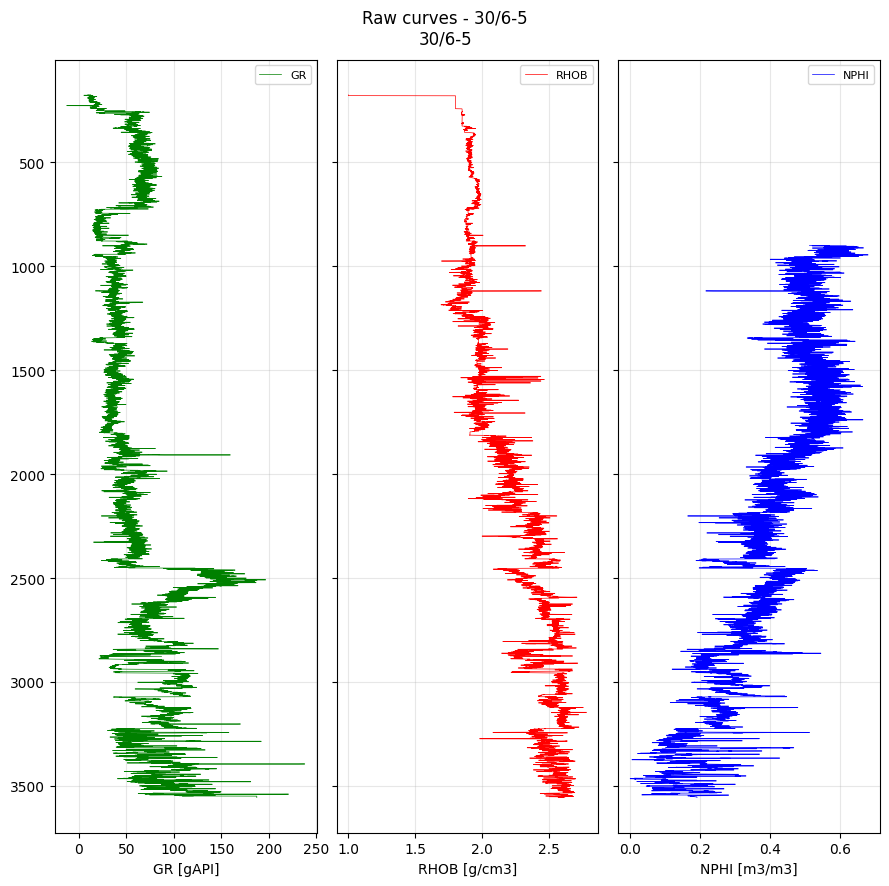

In [11]:
# Raw multi-curve depth display via the library LogPlot (one track per curve).
from petrophys.visualization import LogPlot

lp = LogPlot(w, figsize=(9, 9))
lp.create_figure(n_tracks=3)
lp.add_curve(0, 'GR', color='green')
lp.add_curve(1, 'RHOB', color='red')
lp.add_curve(2, 'NPHI', color='blue')
lp.add_title('Raw curves - 30/6-5')
lp.show()

## 7. Contrasting curve sets: clastic vs carbonate

Different tools were run on the two datasets, so their curve inventories differ. Let us load
the carbonate well `HW-3` and compare its curves with the clastic `30_6-5`.

In [12]:
wc = read_las(petrophys.sample('HW-3'))

set_geo = set(w.curves)
set_car = set(wc.curves)

print('30_6-5 (clastic) curves :', sorted(set_geo))
print()
print('HW-3   (carbonate) curves:', sorted(set_car))
print()
print('Shared by both   :', sorted(set_geo & set_car))
print('Only in 30_6-5   :', sorted(set_geo - set_car))
print('Only in HW-3     :', sorted(set_car - set_geo))

30_6-5 (clastic) curves : ['BS', 'CALI', 'DRHO', 'DTC', 'DTE', 'GDEN', 'GR', 'KH_CORE', 'KV_CORE', 'LITHOLOGY_GEOLINK', 'NPHI', 'PEF', 'PHIC', 'RDEP', 'RHOB', 'RMED', 'RSHA', 'SOC', 'SP', 'SWC']

HW-3   (carbonate) curves: ['DT', 'GR', 'NPHI', 'PERM_CC', 'PHIE_CC', 'RHOB', 'RT', 'SW_INPUT']

Shared by both   : ['GR', 'NPHI', 'RHOB']
Only in 30_6-5   : ['BS', 'CALI', 'DRHO', 'DTC', 'DTE', 'GDEN', 'KH_CORE', 'KV_CORE', 'LITHOLOGY_GEOLINK', 'PEF', 'PHIC', 'RDEP', 'RMED', 'RSHA', 'SOC', 'SP', 'SWC']
Only in HW-3     : ['DT', 'PERM_CC', 'PHIE_CC', 'RT', 'SW_INPUT']


What the comparison tells us:

- **Shared core logs** - `GR`, `RHOB`, `NPHI` - are the common denominator; most workflows
  can run on either well.
- **`30_6-5` is richer**: multiple resistivities (`RDEP`/`RMED`/`RSHA`), sonic (`DTC`/`DTE`),
  `PEF`, `CALI`/`BS`, plus core `PHIC`/`KH_CORE`/`KV_CORE`.
- **`HW-3` uses different names for the same idea**: sonic is `DT` (vs `DTC`), true
  resistivity is `RT` (vs `RDEP`), and its core data is `PHIE_CC`/`PERM_CC`/`SW_INPUT`.
- The units differ too - Costa is in **feet**, Geolink in **metres**.

Those naming and unit differences are precisely the problem that **curve standardization**
solves - the subject of notebook 02.

In [13]:
# Same physical quantity, different mnemonics and units across the two wells.
pd.DataFrame([
    {'quantity': 'gamma ray',      '30_6-5': 'GR (%s)' % w.get('GR').unit,
     'HW-3': 'GR (%s)' % wc.get('GR').unit},
    {'quantity': 'bulk density',   '30_6-5': 'RHOB (%s)' % w.get('RHOB').unit,
     'HW-3': 'RHOB (%s)' % wc.get('RHOB').unit},
    {'quantity': 'sonic',          '30_6-5': 'DTC (%s)' % w.get('DTC').unit,
     'HW-3': 'DT (%s)' % wc.get('DT').unit},
    {'quantity': 'true resistivity','30_6-5': 'RDEP (%s)' % w.get('RDEP').unit,
     'HW-3': 'RT (%s)' % wc.get('RT').unit},
    {'quantity': 'depth unit',     '30_6-5': w.depth_unit, 'HW-3': wc.depth_unit},
])

,quantity,30_6-5,HW-3
0,gamma ray,GR (gAPI),GR (gAPI)
1,bulk density,RHOB (g/cm3),RHOB (g/cm3)
2,sonic,DTC (us/ft),DT (us/ft)
3,true resistivity,RDEP (ohm.m),RT (ohm.m)
4,depth unit,m,ft


## Pitfalls and parameter choices

- **`get`, not `get_curve`.** The accessor is `w.get(mnemonic)`.
- **`valid_count` / `null_count` are methods** - remember the `()`. Forgetting it returns a
  bound method, not a number.
- **Statistics drop nulls.** A `mean()` over a mostly-null core curve reflects only the few
  measured samples. Always sanity-check `pct_valid` before trusting a summary statistic.
- **Curves are aligned to `w.depth`.** Never assume two wells share an index - slice and
  compare on depth, not on sample number.
- **Same physics, different names.** `DTC` vs `DT`, `RDEP` vs `RT` - do not hard-code
  mnemonics across a multi-well project; standardize first (notebook 02).

## Recap

- `read_las` (and `read_dlis`) return a **`Well`**: `name`, `header.field`/`header.uwi`,
  `n_curves`, `n_samples`, `depth`/`depth_unit`, `start_depth`/`stop_depth`/`step`.
- `w.get(mnemonic)` returns a **`Curve`** with `.data`, `.unit`, `.mnemonic`, statistics
  (`mean/min/max/std/median/percentile`), `valid_count()`/`null_count()`, and `.describe()`.
- Guard lookups with `has_curve`/`has_curves`; export with `to_dataframe()`; zoom with
  `depth_slice()`.
- Clastic (`30_6-5`) and carbonate (`HW-3`) wells share core logs but differ in extra
  curves, mnemonics, and units - motivating the QA/QC work ahead.

## Try it yourself

> **Exercise 1.** Write a function `coverage(well)` that returns a DataFrame of every curve's
> `pct_valid`, sorted ascending. Run it on `HW-3` - which curves are sparse there?
>
> **Exercise 2.** Slice `30_6-5` to the interval 2600-2700 m and compute the RHOB and NPHI
> means for that zone. Compare with the whole-well means. Is this interval more or less
> porous than average? (Higher NPHI and lower RHOB generally mean more porosity.)
>
> **Exercise 3.** For `HW-3`, plot `PHIE_CC` (core porosity) and `PERM_CC` (core perm) vs
> depth on two tracks. Where in the well is the best reservoir quality?

## What's next

Continue with **`02_qaqc_and_standardization.ipynb`**. Now that you can read a well and its
curves, we condition the data: standardize mnemonics and units, flag bad-hole intervals with
the caliper, apply value-range QC, and normalize a curve across the Costa field so multi-well
comparisons become meaningful.